# 06 — LSTM Sequence Model

The tabular models see the observation period **collapsed into summary
statistics**. Two players with identical `play_count` and `active_days` look
identical to XGBoost even if one decayed steadily and the other binged on day 4.

An LSTM instead reads the window as an **ordered sequence of days**, so it can
learn the *shape* of engagement rather than only its volume.

In [1]:
import sys, warnings
from pathlib import Path

# Allow `from src import ...` when the notebook is run from notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: D:\bhanu_fyp\player-churn-ml


In [2]:
import torch
from src import config, labeling, features, modeling, sequence

GAME = "game1"
OP, CP = config.OBSERVATION_PERIOD_DAYS, config.CHURN_PREDICTION_PERIOD_DAYS

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

events = pd.read_parquet(config.INTERIM_DIR / f"{GAME}_events.parquet")
cohort = labeling.build_cohort(events, OP, CP)

torch 2.10.0+cpu | CUDA available: False
  cohort: 25,956 players -> 25,422 after left guard -> 25,121 after right guard -> 25,121 with OP activity | churn rate 92.6%


## Sequence construction

Each player becomes an `(OP_days × channels)` tensor, one row per day of the
observation window:

| Channel | Meaning |
|---------|---------|
| `plays` | events that day |
| `active` | played at all that day |
| `session_count` | distinct sessions (30-min inactivity gap) |
| `playtime_min` | minutes between first and last event |
| `mean_score` | average score |
| `spend` | in-game currency spent |
| `win_rate` | share of successful attempts |

In [3]:
X, y, player_ids = sequence.build_sequences(events, cohort, OP)
print(f"X: {X.shape}  (players, days, channels)")
print(f"channels: {sequence.CHANNELS}")
print(f"churn rate: {y.mean():.2%}")

X: (25121, 5, 7)  (players, days, channels)
channels: ['plays', 'active', 'session_count', 'playtime_min', 'mean_score', 'spend', 'win_rate']
churn rate: 92.60%


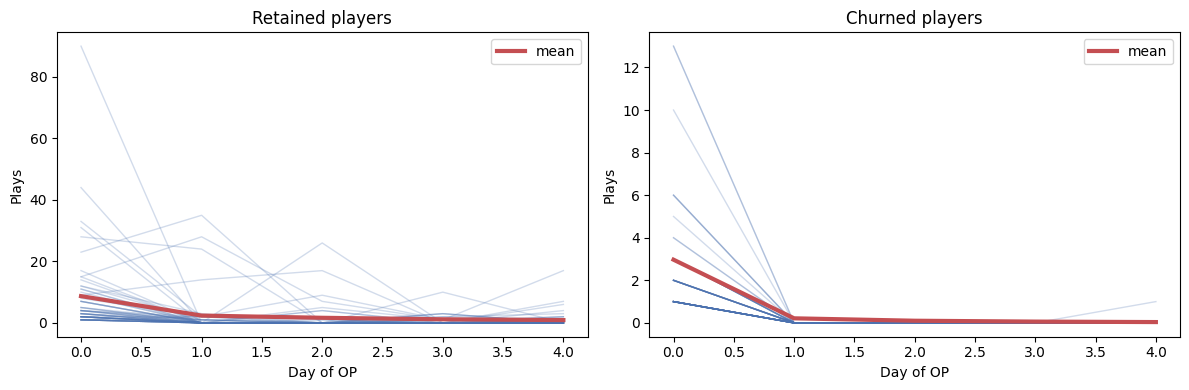

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (label, name) in zip(axes, [(0, "Retained"), (1, "Churned")]):
    idx = np.where(y == label)[0][:60]
    for i in idx:
        ax.plot(range(X.shape[1]), X[i, :, 0], alpha=0.25, lw=1, color="#4C72B0")
    ax.plot(range(X.shape[1]), X[y == label, :, 0].mean(axis=0),
            lw=3, color="#C44E52", label="mean")
    ax.set(xlabel="Day of OP", ylabel="Plays", title=f"{name} players")
    ax.legend()

plt.tight_layout()
plt.show()

## Training

The split is **identical** to the tabular models', so the comparison is
like-for-like. A validation slice is carved out of the training indices only,
used for early stopping on ROC-AUC; the test set is never touched during
training. Channels are z-scored using **training statistics only**.

In [5]:
feats = features.prune_features(features.build_features(events, cohort, OP))
split = modeling.make_split(feats)

model, proba, y_test = sequence.train_lstm(
    X, y, split.train_idx, split.test_idx, epochs=40, verbose=True)

  dropped 2 uninformative columns: std_gap_hours, activity_slope


    epoch   1 | loss 0.1043 | val ROC-AUC 0.8042


    epoch   5 | loss 0.0827 | val ROC-AUC 0.8086


    epoch  10 | loss 0.0818 | val ROC-AUC 0.8102


    epoch  15 | loss 0.0814 | val ROC-AUC 0.8105


    early stop at epoch 17 (best val AUC 0.8107)


In [6]:
lstm_metrics = modeling.evaluate(pd.Series(y_test), proba)
pd.Series(lstm_metrics).to_frame("lstm").round(4)

,lstm
roc_auc,0.7834
pr_auc_churn,0.9705
pr_auc_retained,0.3538
baseline_pr_churn,0.9260
baseline_pr_retained,0.0740
lift_retained,4.7795
balanced_accuracy,0.5622
f1_churn,0.9640
f1_retained,0.2172
brier,0.1724


## Comparison against the tabular models

In [7]:
tabular, _ = modeling.train_all(feats, GAME, do_cv=False)

row = pd.DataFrame([{**lstm_metrics, "model": "lstm", "game": GAME}])
comparison = pd.concat([tabular, row], ignore_index=True)

cols = ["model", "roc_auc", "pr_auc_retained", "baseline_pr_retained",
        "lift_retained", "balanced_accuracy", "brier"]
comparison[cols].sort_values("roc_auc", ascending=False).round(4)

  train 20,096 / test 5,025 | 29 features | churn rate train 92.6%


    logistic_regression    ROC-AUC 0.7736 | PR-AUC(retained) 0.3372 (base 0.0740) | balanced acc 0.5519 | 0.2s


    random_forest          ROC-AUC 0.7280 | PR-AUC(retained) 0.2946 (base 0.0740) | balanced acc 0.5712 | 4.4s


    xgboost                ROC-AUC 0.7418 | PR-AUC(retained) 0.3008 (base 0.0740) | balanced acc 0.5838 | 2.9s
  best model by ROC-AUC: logistic_regression


,model,roc_auc,pr_auc_retained,baseline_pr_retained,lift_retained,balanced_accuracy,brier
3,lstm,0.7834,0.3538,0.074,4.7795,0.5622,0.1724
0,logistic_regression,0.7736,0.3372,0.074,4.5552,0.5519,0.1676
2,xgboost,0.7418,0.3008,0.074,4.0633,0.5838,0.1321
1,random_forest,0.7280,0.2946,0.074,3.9798,0.5712,0.0855


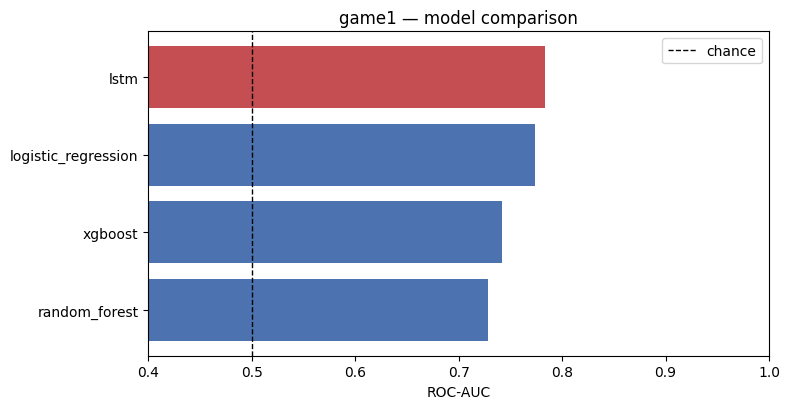

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = comparison.sort_values("roc_auc")
ax.barh(d["model"], d["roc_auc"],
        color=["#C44E52" if m == "lstm" else "#4C72B0" for m in d["model"]])
ax.axvline(0.5, ls="--", c="k", lw=1, label="chance")
ax.set(xlabel="ROC-AUC", xlim=(0.4, 1.0), title=f"{GAME} — model comparison")
ax.legend()
plt.tight_layout()
plt.show()

### Interpreting the comparison

If the LSTM wins, temporal shape carries information the aggregates lose. If it
does not, the summary statistics already capture what matters — which is itself
a useful negative result, and the honest thing to report.

Note the trade-off for the research question: the LSTM offers **no
straightforward feature attribution**. Where explanations drive interventions,
a slightly weaker but fully explainable gradient-boosted model may be the better
operational choice. That tension between accuracy and actionability is worth
discussing directly in the report.